# How useful are COT reports? Every market in `data/`

**In one sentence:** across 17 markets, the COT report is a good **description** of what big speculators are
doing (they move in clear, lasting regimes, chase the price and pull back from extreme bets), but it is **not a
forecast**: in no market did it predict the next price move, its direction, or when a big move was coming.

The rest of this notebook shows how we got there, one plain-language step at a time.

**How to read it:** each step starts with *what we are doing and why*, then shows the result, then says *what it
means*. Words in **bold** are explained in the glossary below. The gold notebook (`cot_report_analysis-1.ipynb`)
covers each method in more depth, using gold as the example.

*Numbers quoted in the text are as of the 13 October 2026 report; the charts and tables update whenever you
re-run the notebook.*

## What this notebook does

The **COT (Commitments of Traders) report** is published every Friday by the US regulator (the CFTC). It shows
how many futures contracts different groups of traders hold. We follow the **large speculators**: funds and big
traders betting on prices.

For gold we found four things:
1. Speculators move between a few recurring positioning states (**regimes**).
2. Their positioning swings back from extremes.
3. They move *with* the price, not ahead of it.
4. Nothing in the report predicts the price or big moves.

**Here we ask: is gold special, or is this true of COT reports in general?** We run exactly the same checks on all
17 markets in `data/`: 9 currencies, 2 stock indices, 4 metals, crude oil and bitcoin. Each market is compared
with its own daily futures price from Yahoo Finance.

## Words used in this notebook

| Word | Plain meaning |
|---|---|
| **Long / short** | A long bet profits if the price rises; a short bet profits if it falls |
| **Net position** | Longs minus shorts, here as a share of all open contracts (so big and small markets compare fairly) |
| **Open interest** | The total number of open contracts: how big the market is |
| **3-year percentile** | Where this week's net position sits compared with the last 3 years (0% = most short, 100% = most long) |
| **Regime** | A recurring "state" the market is in, found by grouping similar weeks |
| **K-Means** | The grouping method: drop 4 pins on the data, each week joins its nearest pin, pins move to the middle of their group, repeat |
| **Most short / Leaning short / Leaning long / Most long** | The 4 regimes in every market, ranked by their average net position **within that market**. "Long" means long *compared with what's usual there*: in the Swiss franc even "Leaning long" averages slightly net short, because speculators are usually short the franc |
| **Separation** (silhouette) | How clearly each week belongs to its regime (closer to 1 = clearer) |
| **Stability** | Re-run on random 80% slices of history: do the same regimes come back? (1 = identical every time) |
| **Correlation** | How closely two things move together: 1 = always together, 0 = unrelated, -1 = always opposite |
| **p-value** | Roughly, how likely a result this strong would be if nothing were really going on. Small (below 0.05) = probably real |
| **Testing many markets at once** | With 17 markets, about 1 test in 20 looks convincing by pure luck. We raise the bar to allow for that (the **Benjamini-Hochberg adjustment**) so that few of our "yes" answers can be flukes |
| **Big move** | The price rising *or* falling by a lot over the next 4 weeks: the largest 20% of moves in that market |
| **Jumpiness** (volatility) | How much the price has been swinging week to week over the last 13 weeks |
| **Non-overlapping weeks** | When we look 8 (or 4) weeks ahead, neighbouring weeks share most of the same future. Testing every week would count the same move many times, so tests use one week in every 8 (or 4) |

## Step 1: load every market

**What we do:** read each market's weekly COT file from `data/` and its saved daily prices from `data/prices/`.
The prices were downloaded once with `python scripts/fetch_prices.py --all`; the notebook only reads the saved
files.

**Two clean-ups happen automatically:**
- When two contracts of a market were reported in the same week (for example after an exchange was renamed),
  we keep the one with the most open contracts, the same rule the data pipeline uses.
- One bad price was found and removed: the Japanese yen on 17 December 2001 has a misplaced decimal point (the
  price drops to a tenth for one day, then comes straight back).

In [1]:
import sys
from pathlib import Path

# make the project importable whether the notebook runs from docs/ or the project folder
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd

import config
from cot_pipeline import market_plots, market_scan
from cot_pipeline.prices import price_file, read_saved_prices

%matplotlib inline

raw_by_symbol = {s: pd.read_csv(config.DATA_DIR / f"{s}.csv") for s in config.SYMBOL_NAMES}
prices_by_symbol = {s: read_saved_prices(price_file(s)) for s in config.SYMBOL_PRICE_TICKERS}

pd.DataFrame(
    [
        {
            "Market": config.MARKET_LABELS[s][0],
            "Type": config.MARKET_LABELS[s][1],
            "Price (Yahoo ticker)": config.SYMBOL_PRICE_TICKERS[s],
            "COT reports": len(raw_by_symbol[s]),
            "Prices from": f"{prices_by_symbol[s]['date'].min():%Y-%m-%d}",
        }
        for s in config.MARKET_LABELS
    ]
)

Dropped price spike on 2001-12-17 (close 0.0007830000249668): out of line with the days either side


,Market,Type,Price (Yahoo ticker),COT reports,Prices from
0,Euro,Currencies,6E=F,1364,2000-09-12
1,Japanese yen,Currencies,6J=F,1939,2000-09-13
2,British pound,Currencies,6B=F,1819,2000-10-05
3,Swiss franc,Currencies,6S=F,1937,2000-11-10
4,Canadian dollar,Currencies,6C=F,1939,2000-05-23
5,Australian dollar,Currencies,6A=F,1802,2000-11-08
6,New Zealand dollar,Currencies,6N=F,1158,2000-06-09
7,Mexican peso,Currencies,6M=F,1640,2001-06-18
8,US dollar index,Currencies,DX-Y.NYB,1873,2000-01-03
9,Dow Jones,Stock indices,YM=F,1496,2002-04-05


## Step 2: run the same checks on every market

**What we do:** for each market, the same steps as for gold:
1. Group its weeks into **4 regimes** with K-Means, using where speculators stand (longs and shorts as a share of
   the market, plus the 3-year percentile).
2. Measure how clear and repeatable the regimes are.
3. Check what speculators did over the next 8 weeks after each regime: does positioning swing back?
4. Compare speculators' weekly buying or selling with the price change in the **same** week and the **next** week.
5. Check the price over the 8 weeks after each regime is published.
6. Check whether anything known on report day warned of a **big move**, or hinted at its direction.

Then every p-value is adjusted for testing 17 markets at once. *This cell takes about 15 seconds.*

In [2]:
summary, labelled_by_symbol, skipped = market_scan.scan_markets(raw_by_symbol, prices_by_symbol)
print(f"Analysed {len(summary)} markets; skipped: {skipped or 'none'}")
market_scan.question_counts(summary).rename(
    columns={"question": "Question", "markets_yes": "Markets where the answer is yes", "markets": "Out of"}
)

Analysed 17 markets; skipped: none


,Question,Markets where the answer is yes,Out of
0,"Do speculators' positions fall into clear, rep...",15,17
1,Does positioning swing back from extremes over...,15,17
2,Do speculators buy when the price rises (same ...,15,17
3,Does speculators' buying or selling come befor...,0,17
4,Do the regimes forecast the price over the nex...,0,17
5,Does a jumpy price warn of a big move in the n...,15,17
6,Does anything in the COT report warn of a big ...,0,17
7,Does the COT report hint whether a big move wi...,0,17


## Step 3: the scorecard, every market and every question at once

**How to read it:** one row per market, grouped by type. One column per question. A **filled blue dot** means
"yes, convincingly", after allowing for testing 17 markets. An **open dot** means no, or "could be luck". The
numbers at the bottom count the yeses.

The columns **left of the vertical line** ask whether the COT report *describes* the crowd. The columns **right of
it** ask whether anything *warns* of what the price will do.

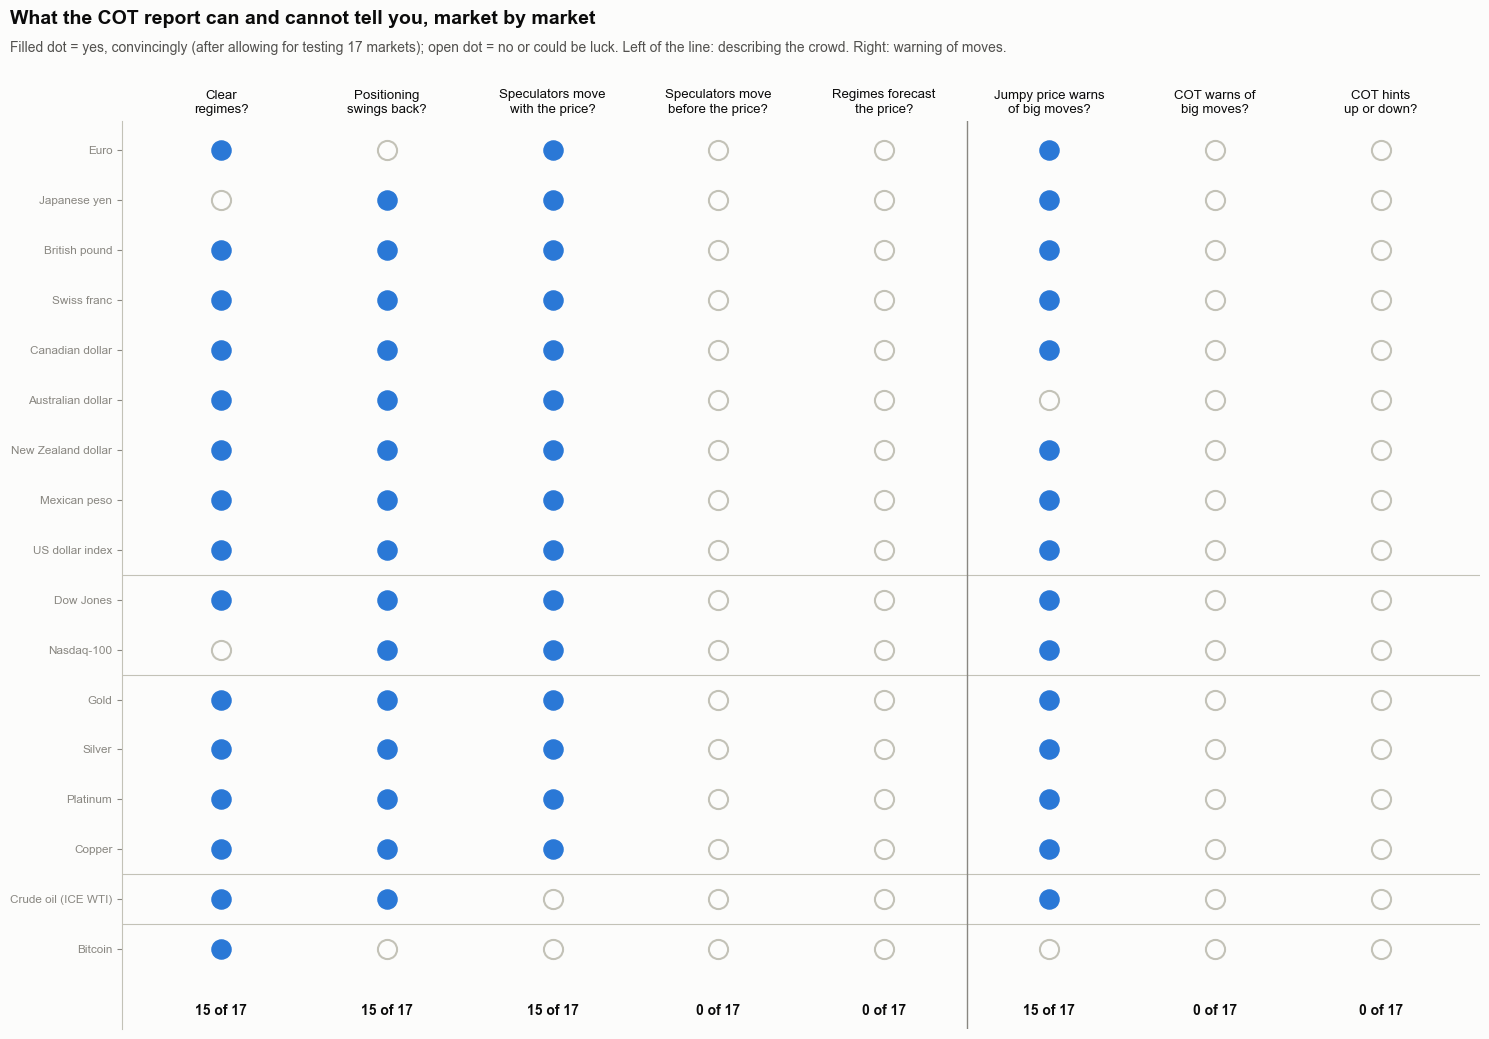

In [3]:
market_plots.scorecard_figure(summary);

**What it shows:**
- **Left side, nearly all filled:** in almost every market, speculators' positions fall into clear regimes, swing
  back from extremes, and move with the price.
- **"Speculators move before the price?" and "Regimes forecast the price?": all empty.** In no market does the
  COT report get ahead of the price.
- **"Jumpy price warns of big moves?": nearly all filled.** The one reliable early warning is the price itself.
- **"COT warns of big moves?" and "COT hints up or down?": all empty.**

So gold was not special. **The same pattern holds across currencies, stock indices, metals and energy.**

## Step 4: what positioning looks like in each market
**How to read it:** one small chart per market. Each dot is one week's net position: above 0 = speculators
net long, below 0 = net short. Colours show the regime, found separately for each market, from most short
(orange) to most long (blue).

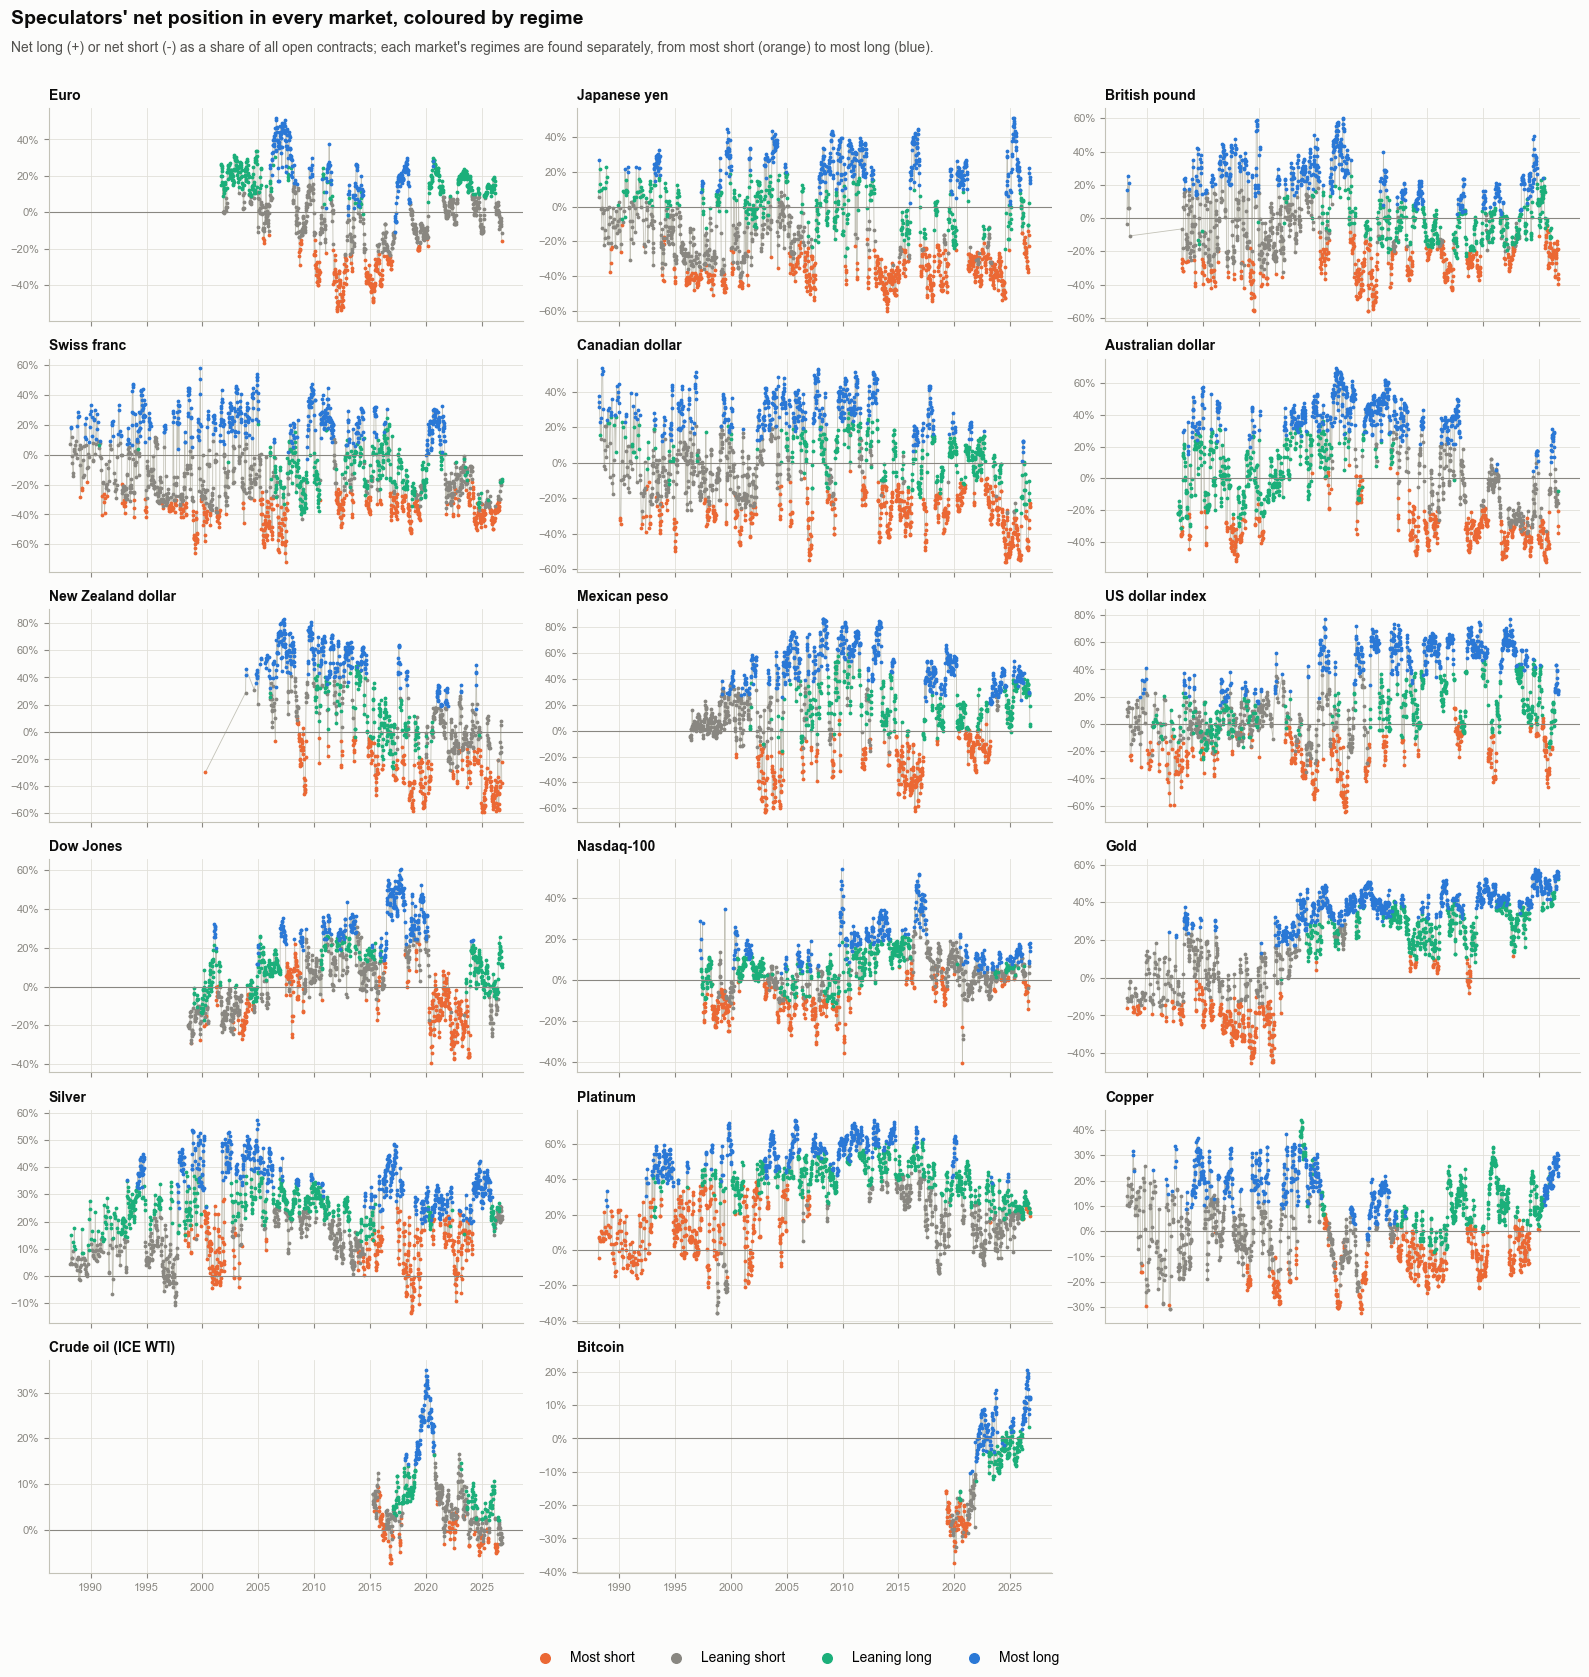

In [4]:
market_plots.positioning_small_multiples(labelled_by_symbol);

**What it shows:** every market spends weeks to months in one regime before moving on. Speculators are
not random week to week; they hold views for a while. Some markets lean long most of the time (gold, platinum,
silver, the US dollar index); others swing between long and short (the yen, the Swiss franc, the Canadian
dollar).

## Step 5: does positioning swing back from its extremes?
**The question:** after speculators are at their **most short**, do they tend to buy back? After their **most
long**, do they tend to trim?

**How to read it:** for each market, the orange dot is how often speculators were *more long* 8 weeks after their
most-short regime. The blue dot is the same after their most-long regime. The grey line at 50% is a coin flip.
Orange to the right and blue to the left = positioning swings back.

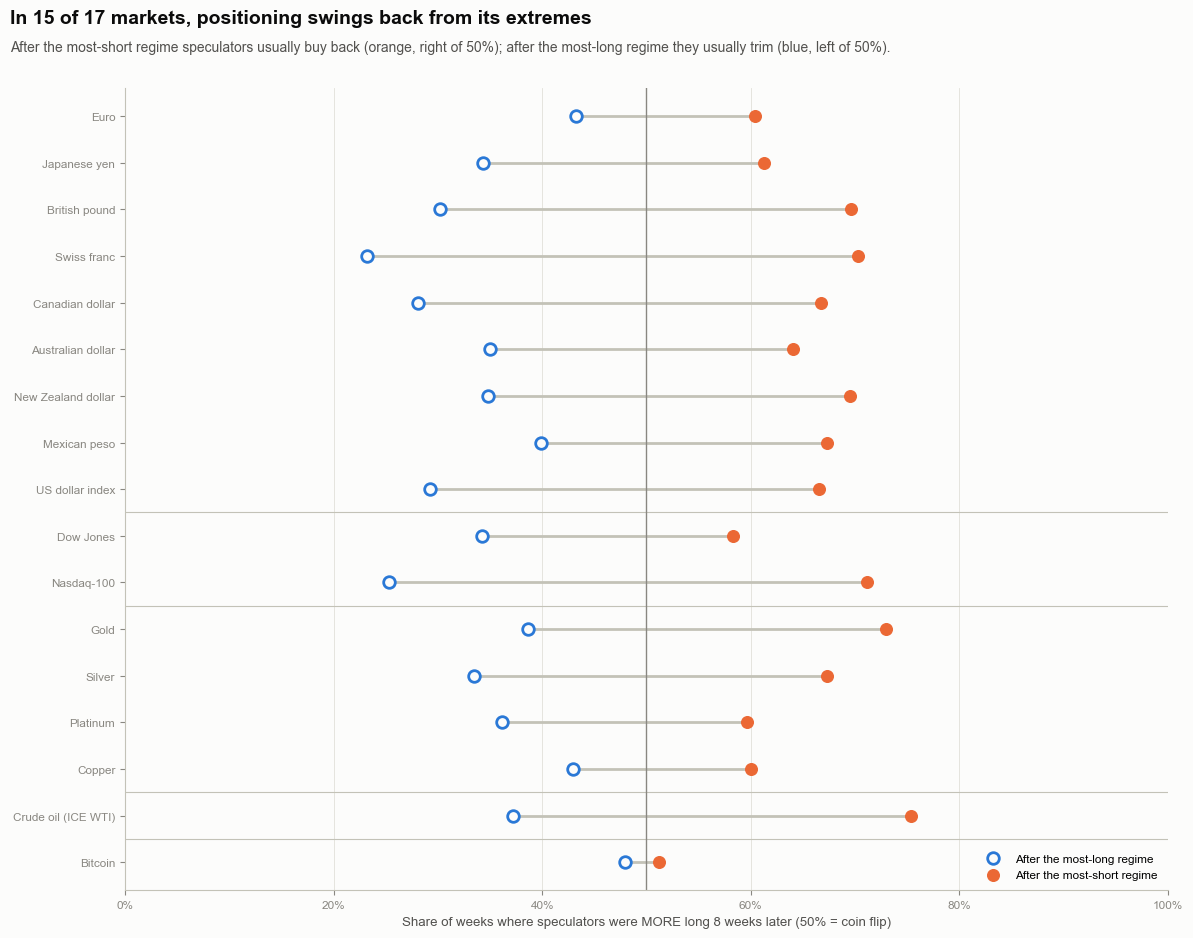

In [5]:
market_plots.reversion_figure(summary);

**What it shows:** in almost every market the dots sit on opposite sides of 50%. **Extreme positioning
does not last; it unwinds.** This is the most consistent thing the COT report tells us about the *crowd*.

The two exceptions are **bitcoin**, which has only about 400 weeks of history, and the **euro**, which leans the
right way but just misses the bar after adjusting for many tests.

**But note:** this is about what speculators do next, **not** what the price does next. The next two steps check
the price.

## Step 6: do speculators move with the price, or ahead of it?
**How to read it:** for each market there are two correlations with speculators' weekly buying or selling. The
**filled dot** is with the price change in the *same* week. The **open dot** is with the price change in the
*next* week. If speculators knew where prices were going, the open dots would sit clearly right of zero.

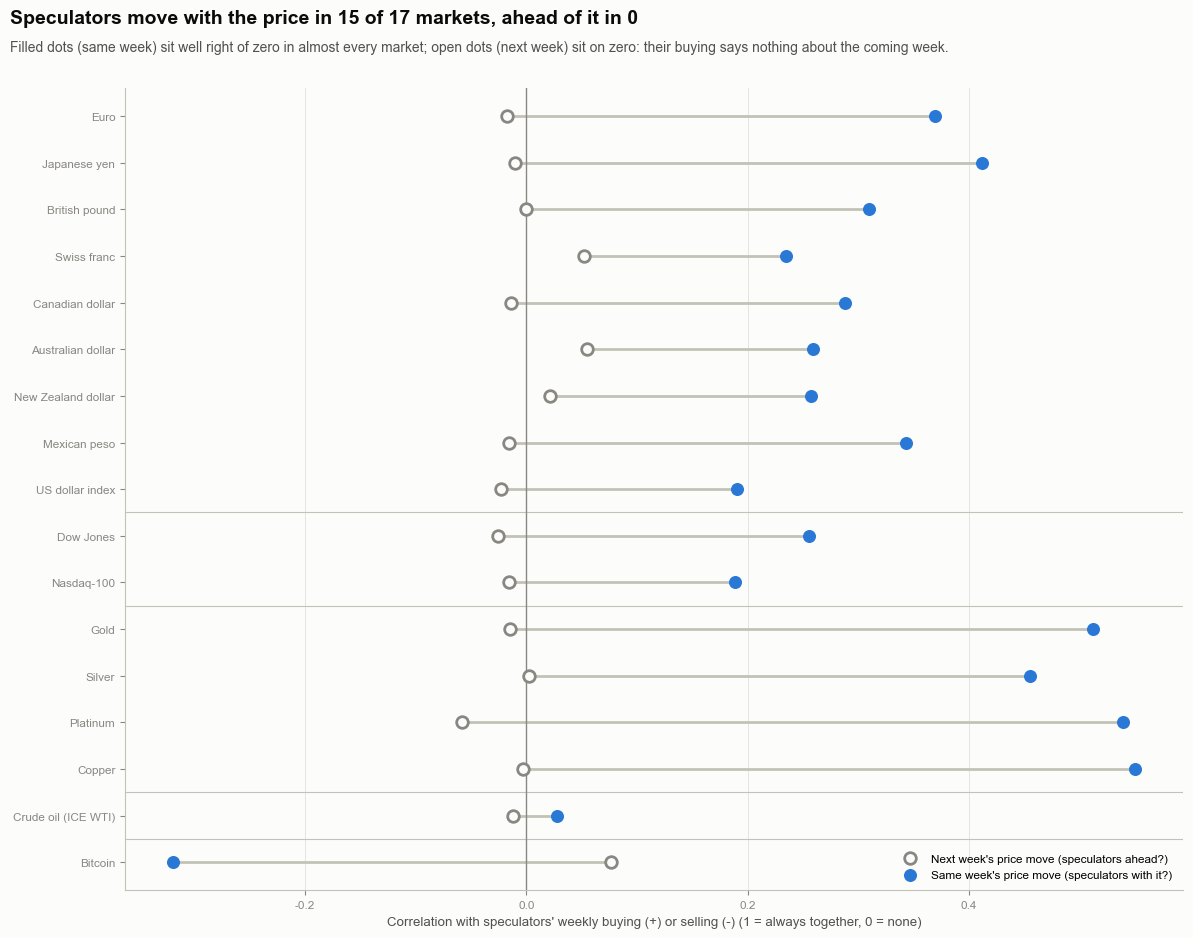

In [6]:
market_plots.follow_not_lead_figure(summary);

**What it shows:**
- **Same week (filled dots): clearly positive in almost every market.** In weeks when the price rises,
  speculators buy, and vice versa. They are **trend followers**.
- **Next week (open dots): all close to zero.** Their buying or selling says nothing about the coming week.
- **Bitcoin is reversed:** there, "speculators" tend to sell futures when the price rises. A likely reason is that
  many of them are funds running a *basis trade*: they own bitcoin or bitcoin ETFs and sell futures against them,
  selling more when prices rally.
- **Crude oil shows almost no link.** The COT data here covers ICE Europe's WTI contract (only since 2015), a
  smaller copy of the main New York contract, which is probably why.

## Step 7: do the regimes forecast the price?
**How to read it:** the average price change over the 8 weeks **after** the report is published. Orange = after
the most-short regime, blue = after the most-long regime. If extreme positioning predicted reversals ("everyone
is long, so the top is in"), blue would sit clearly left of orange in most markets. On the right is the adjusted
p-value: below 0.05 would mean a real difference.

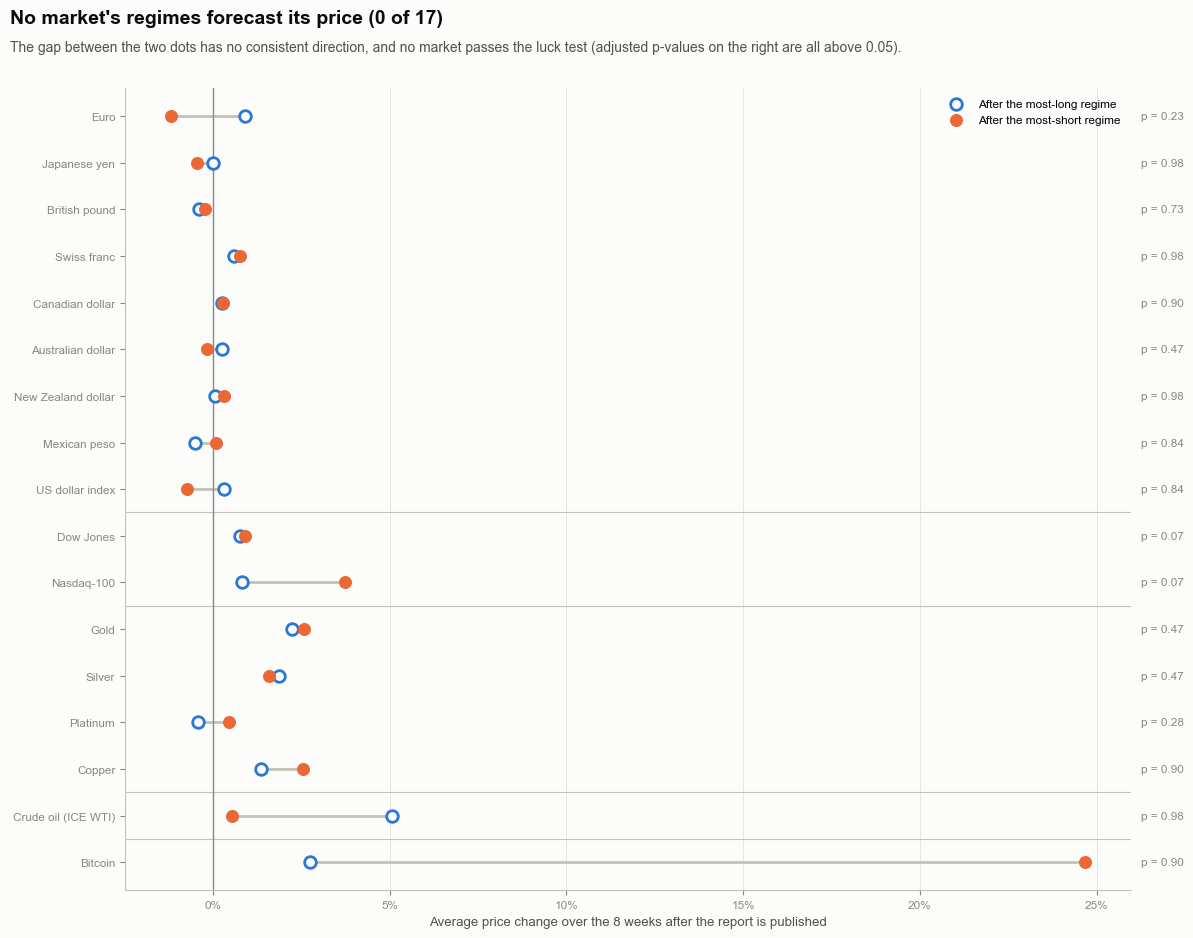

In [7]:
market_plots.price_after_regime_figure(summary);

**What it shows:** the gaps go both ways, most are small, and **every p-value is above 0.05**. Knowing
that speculators are at an extreme does **not** tell you where the price goes next, in any market.

Bitcoin's large orange value comes from very few weeks (bitcoin roughly doubled in some of them), so it is
noise, not a signal: its p-value is 0.90.

## Step 8: can we see a big move coming?
**How to read it:** the chance of a **big move** in the next 4 weeks, after the price's **calmest** 13 weeks (open
dot) and its **jumpiest** 13 weeks (filled dot). The grey line is the normal chance, 20%.

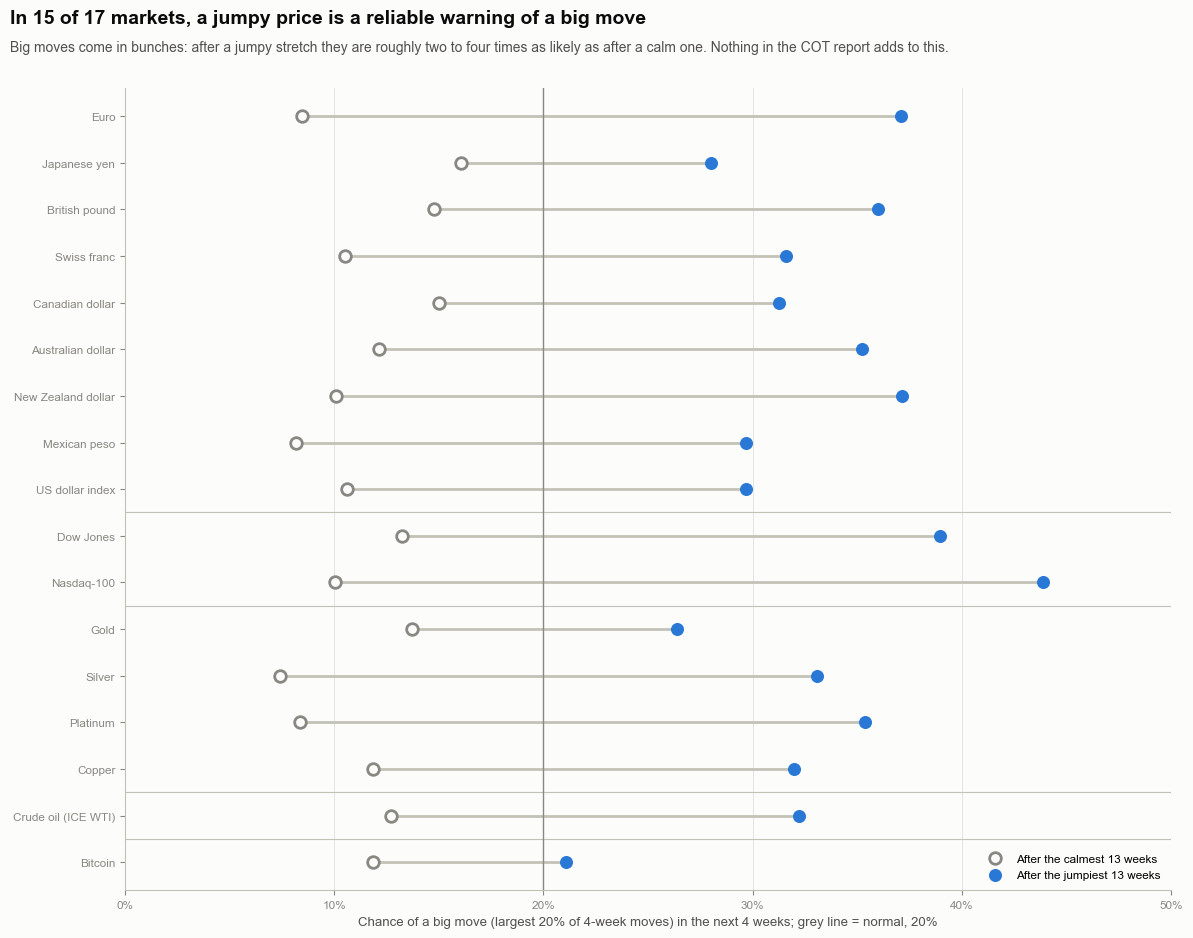

In [8]:
market_plots.big_moves_figure(summary);

**What it shows:**
- **In 15 of 17 markets a big move is clearly more likely after a jumpy stretch**, often 2-4 times as likely as
  after a calm one. Big moves come in bunches; markets call this *volatility clustering*. Australia and bitcoin
  point the same way but don't pass the luck test.
- **None of the COT clues** (how much speculators just bought or sold, how fast open interest changed, how extreme
  positioning was) raised the odds of a big move in any market.
- **The direction of a big move** (a buy or a dump) was not hinted at by speculators' positioning or their recent
  buying in any market.

**A near miss worth knowing about.** Our first version of the direction test said "yes" in 5 markets. It used
every week, but neighbouring weeks share the same 4-week move, so each big move was counted several times and
the evidence looked stronger than it was. Re-done properly, using one week in every four, the answer was "no"
everywhere. This is a common trap with market data, and the main reason to be wary of COT "signals" you see
advertised.

## Step 9: every market in one table

| Column | Meaning |
|---|---|
| Separation / Stability | How clear and repeatable the regimes are |
| Added after most short / most long | How often speculators were more long 8 weeks after their most-short / most-long regime |
| Same-week / Next-week link to price | Correlation of speculators' weekly change with the price change that week / the next week |
| p: regimes forecast price | Adjusted p-value; above 0.05 = could easily be luck |
| Big move: calm / jumpy | Chance of a big 4-week move after the calmest / jumpiest 13 weeks (normally 20%) |
| Latest regime | Where speculators stand in the most recent report |

In [9]:
market_plots.summary_table(summary)

,Market,Weeks,Separation,Stability,Added after most short,Added after most long,Same-week link to price,Next-week link to price,p: regimes forecast price,Big move: calm / jumpy,Latest regime
0,Euro,1313,0.33,0.95,60%,43%,0.37,-0.02,0.23,8% / 37%,Most short
1,Japanese yen,1888,0.35,0.77,61%,34%,0.41,-0.01,0.98,16% / 28%,Most long
2,British pound,1768,0.35,0.97,70%,30%,0.31,-0.00,0.73,15% / 36%,Most short
3,Swiss franc,1886,0.34,0.90,70%,23%,0.24,0.05,0.98,11% / 32%,Leaning long
4,Canadian dollar,1888,0.35,0.89,67%,28%,0.29,-0.01,0.90,15% / 31%,Most short
5,Australian dollar,1751,0.38,0.95,64%,35%,0.26,0.06,0.47,12% / 35%,Most short
6,New Zealand dollar,1107,0.35,0.98,70%,35%,0.26,0.02,0.98,10% / 37%,Most short
7,Mexican peso,1589,0.37,0.94,67%,40%,0.34,-0.02,0.84,8% / 30%,Leaning long
8,US dollar index,1822,0.36,0.84,67%,29%,0.19,-0.02,0.84,11% / 30%,Most long
9,Dow Jones,1445,0.31,0.97,58%,34%,0.26,-0.03,0.07,13% / 39%,Leaning long


## Step 10: where speculators stand right now
**What it is:** the regime of the most recent report in each market. **How to use it:** as a description of the
crowd today, *not* as a trade signal. Steps 5 and 7 showed that extremes tend to unwind in **positioning**, but
that this does not reliably show up in the **price**.

**Why a regime name can look odd next to its net position:** a week is assigned to the regime whose *average
week* it most resembles, judged on longs, shorts and the 3-year percentile together, not on net position
alone. So the Swiss franc can be "Leaning long" at -16% net: speculators there are usually even more short, and
this week sits in the upper part of its 3-year range.

In [10]:
latest = market_plots.ordered(summary)[["label", "group", "last_week", "latest_regime", "latest_net_share"]]
latest.rename(columns={"label": "Market", "group": "Type", "last_week": "Report date", "latest_regime": "Regime",
                       "latest_net_share": "Net position (share of market)"}).round(2)

,Market,Type,Report date,Regime,Net position (share of market)
0,Euro,Currencies,2026-10-13,Most short,-0.16
1,Japanese yen,Currencies,2026-10-13,Most long,0.13
2,British pound,Currencies,2026-10-13,Most short,-0.40
3,Swiss franc,Currencies,2026-10-13,Leaning long,-0.16
4,Canadian dollar,Currencies,2026-10-13,Most short,-0.25
5,Australian dollar,Currencies,2026-10-13,Most short,-0.35
6,New Zealand dollar,Currencies,2026-10-13,Most short,-0.38
7,Mexican peso,Currencies,2026-10-13,Leaning long,0.05
8,US dollar index,Currencies,2026-10-13,Most long,0.25
9,Dow Jones,Stock indices,2026-10-13,Leaning long,0.10


## Conclusion: how useful are COT reports?

**What the COT report is good for**
- **Seeing the crowd.** It reliably shows whether big speculators are heavily long, heavily short or in between,
  in every market we tested.
- **Knowing that extremes unwind.** When speculators are at their most long or most short, their positions tend
  to swing back over the following weeks. That makes the report useful for understanding *crowding* and
  *positioning risk*.
- **Context for the trend.** Speculators move with the price. Their positioning is a running record of the trend
  that has already happened, with who is on which side of it.

**What the COT report is not good for**
- **Forecasting the price.** In none of the 17 markets did speculators' positioning, its regime, or its recent
  change predict the next week's or the next 8 weeks' price, after allowing for testing many markets.
- **Timing big moves.** Nothing in the report warned of big moves or their direction. The only reliable warning
  of a big move was the price being jumpy already.
- **One-week-old news.** Positions are as of Tuesday and published on Friday. Since speculators move *with* the
  price, by publication the move they reflect has usually already happened.

**In practice:** treat the COT report as a **map of who is positioned where**, alongside price and volatility,
not as a signal on its own.

**Caveats**
- Everything describes the past: the models were fitted on each market's full history, not tested on unseen data.
- Prices are continuous front-month futures from Yahoo Finance, which switch contracts every few months.
- Bitcoin (about 400 weeks) and ICE crude oil (from 2015) have short histories, so their results are less certain.
- We tested 8-week and 4-week horizons and weekly links; other horizons or other trader groups (for example
  commercial hedgers) could behave differently.

**Possible next steps:** look at the commercial hedgers' positions; test longer horizons (3-6 months); try a
time-aware model (a hidden Markov model) of how regimes hand over to each other.

The same results are written up in `reports/cot_all_markets.md` (`python scripts/cot_all_markets.py`
regenerates it) and in `reports/cot_all_markets.csv`.

## Further reading

Beginner-friendly first:
1. **StatQuest with Josh Starmer** (short, friendly YouTube videos). Search "StatQuest K-means", "StatQuest
   p-values" and "StatQuest false discovery rate": https://www.youtube.com/@statquest
2. James, Witten, Hastie & Tibshirani, ***An Introduction to Statistical Learning*** (2nd ed., free PDF), chapter
   12 "Unsupervised Learning" and chapter 13 "Multiple Testing": https://www.statlearning.com
3. CFTC, **"Commitments of Traders: explanatory notes"** (what each COT column means):
   https://www.cftc.gov/MarketReports/CommitmentsofTraders/ExplanatoryNotes/index.htm
4. Briese, S. (2008). ***The Commitments of Traders Bible***. Wiley.

More technical:

5. Wang, C. (2003). The behavior and performance of major types of futures traders. *Journal of Futures Markets*,
   23(1), 1-31.
6. Benjamini, Y. & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to
   multiple testing. *Journal of the Royal Statistical Society, Series B*, 57(1), 289-300.
7. Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis.
   *Journal of Computational and Applied Mathematics*, 20, 53-65.